# Proches en métro, proches en revenus ?

## *La géographie du réseau de transports en communs en Île-de-France reflète-t-elle la géographie des inégalités de revenus dans la région ?*

## Introduction

*De la Plaine Monceau au quartier des Épinettes on parcourt tout l'espace social, la transition entre les extrêmes étant assurée par un glacis de classes moyennes. Ces contrastes sociaux importants voisinent pourtant à quelques rues près, même si la mixité sociale est menacée par un processus d'embourgeoisement qui fait tache d'huile et ne laisse guère de quartiers à l'écart.*

*Du sud-ouest au nord-est du 17e arrondissement, le parcours est à la fois historique et sociologique, des abords fortunés du parc Monceau aux confins bordés par les boulevards des Maréchaux et leurs HBM (Habitations à bon marché, ancêtres des HLM).*

Pinçon, M. et Pinçon-Charlot, M. (2014). I. Lire Paris. Sociologie de Paris (3e éd., p. 9-26). La Découverte. https://shs.cairn.info/sociologie-de-paris--9782707182623-page-9?lang=fr.

Parce qu'elles sont conçues pour relier des territoires différents, les lignes de transports en commun traversent logiquement des espaces socialement et économiquement hétérogènes. Ainsi, par exemple, l'usager quotidien de la ligne 4 ou du RER A n'occupe pas la même position dans l'échelle sociale selon qu'il se trouve au milieu ou à l'une des extrémités de ces lignes.

Si des territoires économiquement et socialement proches peuvent aussi l'être géographiquement, les transports en commun rapprochent des espaces parfois très différentes, et constituent ainsi des axes le long desquels peuvent s'observer les contrastes.

Nous développons ici deux axes de réponse à cette question. Nous verrons dans un premier temps que les revenus tendent à décroître à mesure que l'excentricité par rapport au réseau augmente, y compris à distance géographique équivalente. Dans un second temps, nous verrons que le long de certaines lignes, des stations très proches affichent des revenus moyens très différents.

## Données

Les deux principales sources de données utilisées pour ce projet sont les données IDFM et les données Filosofi.

In [1]:
from pretraitement_donnees import telecharger_zip, URL_ZIP_FILOSOFI, URL_ZIP_IDFM
import numpy as np
import os
import pandas as pd

### Données FiLoSoFi (2021)

Les données FiLoSoFi sont des données territoriales calculées par l'Insee, sur des carreaux de 200mx200m, ici pour l'année 2021. Lorsque les carreaux contiennent moins de 11 ménages, les données sont imputées pour préserver le secret statistique.

In [ ]:
from pretraitement_donnees import charger_filosofi, indicateurs_filosofi, definir_quantiles, construire_centres_carreaux
from visualisation_donnees import generer_carte_filosofi
import geopandas as gpd

telecharger_zip(URL_ZIP_FILOSOFI, "filosofi")

df_filosofi = gpd.read_file("data/filosofi/france_metro/carreaux_200m_met.shp", rows=1)
print(df_filosofi.columns)

Index(['idcar_200m', 'idcar_1km', 'idcar_nat', 'i_est_200', 'i_est_1km',
       'lcog_geo', 'ind', 'men', 'men_pauv', 'men_1ind', 'men_5ind',
       'men_prop', 'men_fmp', 'ind_snv', 'men_surf', 'men_coll', 'men_mais',
       'log_av45', 'log_45_70', 'log_70_90', 'log_ap90', 'log_inc', 'log_soc',
       'ind_0_3', 'ind_4_5', 'ind_6_10', 'ind_11_17', 'ind_18_24', 'ind_25_39',
       'ind_40_54', 'ind_55_64', 'ind_65_79', 'ind_80p', 'ind_inc',
       'geometry'],
      dtype='str')


Comme ces données sont très volumineuses, le chargement est effectué par la fonction <code>charger_filosofi</code>. Elle récupère, pour l'Île-de-France, les colonnes <code>loc</code> (localisation), <code>ind</code> (nombre de ménages sur le carreau) et <code>ind_snv</code> (somme des niveaux de vie sur le carreau).

<Axes: >

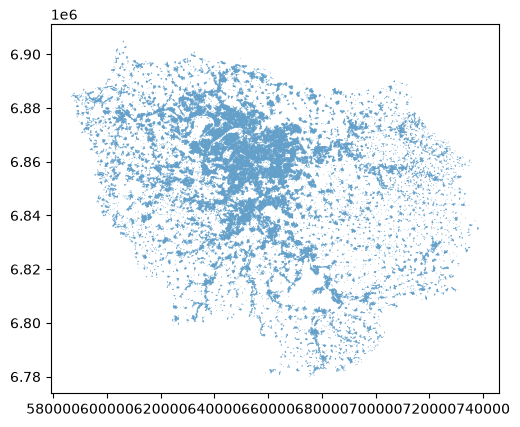

In [5]:
df_filosofi = charger_filosofi("data/filosofi/france_metro/carreaux_200m_met.shp") # Carreaux de 200 m d'Île-de-France
df_filosofi.plot()

In [6]:
df_filosofi.head()

,lcog_geo,ind,ind_snv,geometry
1550427,"77099,45255,45114",3.0,73610.5,"POLYGON ((675221.847 6780022.874, 675203.377 6..."
1551095,"77099,45255",2.0,55295.1,"POLYGON ((676995.101 6780392.708, 676976.633 6..."
1551746,"77099,45255",7.0,155117.9,"POLYGON ((675583.068 6780458.731, 675564.598 6..."
1551747,77099,7.0,177031.0,"POLYGON ((676976.633 6780591.648, 676958.164 6..."
1552403,77099,5.0,110798.5,"POLYGON ((676161.841 6780714.637, 676143.371 6..."


On calcule pour chaque carreau le niveau de vie moyen, ainsi que le sextile pour la visualisation.

In [9]:

df_filosofi = indicateurs_filosofi(df_filosofi) # Niveau de vie moyen par habitant de chaque carreau
df_filosofi = definir_quantiles(df_filosofi, "nv", 6) # Sextiles de niveau de vie, pondérés par la population
print(df_filosofi.describe())

                ind       ind_snv            nv
count  72766.000000  7.276600e+04  72766.000000
mean     162.641398  4.642261e+06  29868.480766
std      292.404690  8.782956e+06   7023.712128
min        1.000000  1.438110e+04   9461.064286
25%       10.000000  3.104306e+05  25428.837941
50%       52.000000  1.561070e+06  29105.667344
75%      178.000000  5.130676e+06  33432.263112
max     7546.000000  1.228427e+08  73663.823333


En 2021, le niveau de vie médian en Île-de-France (sur les carreaux de 200mx200m de plus de 11 ménages) est de 29 105€ par an.

### Données IDFM (2026)

Île-de-France Mobilités (IDFM) propose les données 

In [2]:
from pretraitement_donnees import charger_arrets, charger_routes, charger_horaires, charger_parcours, charger_stations, charger_trips, construire_lignes_idfm, construire_stations, construire_positions_stations, construire_aretes, construire_graphe_reseau

# telecharger_zip(URL_ZIP_IDFM, "idfm")
print(os.listdir("data/idfm"))

['transfers.txt', 'agency.txt', 'calendar_dates.txt', 'stop_times.txt', 'shapes.txt', 'object_codes_extension.txt', 'trips.txt', 'ticketing_deep_links.txt', 'attributions.txt', 'pathways.txt', 'stops.txt', 'booking_rules.txt', 'calendar.txt', 'routes.txt']


Les données IDFM ne contiennent pas moins de 14 fichiers .txt différents, au format CSV. Nous ne chargeons que ceux dont nous avons besoin pour construire les lignes et calculer les temps de trajet entre deux stations. 

In [13]:
print(len(pd.read_csv("data/idfm/routes.txt"))) 

2027


Il y a 2027 lignes différentes. Pour faciliter la visualisation et les traitements, nous décidons de ne garder que les lignes de métro et de RER.

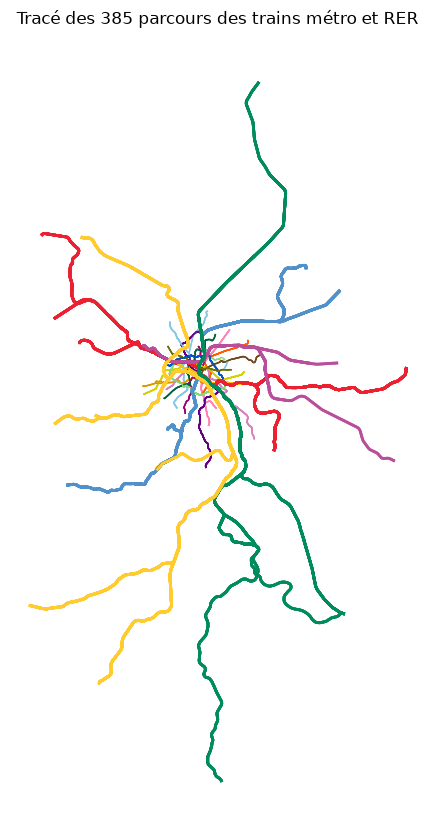

In [3]:
df_routes = charger_routes("data/idfm") # Lignes selon leur type, nous ne gardons que métro et RER
df_trips = charger_trips("data/idfm", df_routes) # Trains qui traversent chaque ligne
df_parcours = charger_parcours("data/idfm", df_trips) # Géométrie du parcours suivi par les trains de notre sélection

gpd_idfm = construire_lignes_idfm(df_parcours) # Passage en GeoPandas, avec changement de projection

ax = gpd_idfm.plot(
    color="#" + gpd_idfm["route_color"], # Couleurs officielles des lignes
    linewidth=np.where(gpd_idfm["mode"] == "metro", 1, 2), # RER plus épais
    figsize=(10, 10),
)
ax.set_title(f"Tracé des {len(gpd_idfm)} parcours des trains métro et RER")
ax.set_axis_off()

Nous obtenons un GeoDataFrame qui contient le tracé géographique de chaque ligne de métro / RER. Remarquons que certaines lignes possèdent de nombreux trains, auxquels correspondent de nombreux tracés.

In [9]:
print(gpd_idfm.reset_index().groupby("route_id").agg({"shape_id":"count", "route_short_name":"first"}).sort_values("shape_id", ascending=False).head(5))

             shape_id route_short_name
route_id                              
IDFM:C01727        83                C
IDFM:C01742        59                A
IDFM:C01728        56                D
IDFM:C01743        47                B
IDFM:C01384        19               14


De la même manière, nous construisons le graphe du réseau à partir des temps de transport d'une station à une autre. Les sommets sont donc les stations, et les sommets les arêtes.

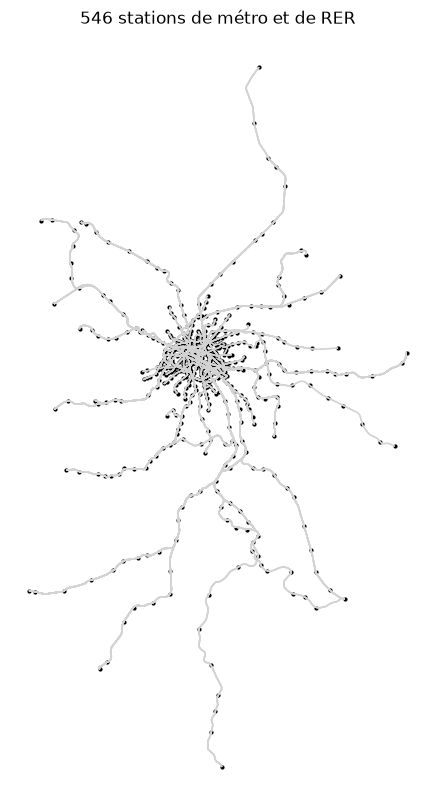

In [15]:
df_arrets = charger_arrets("data/idfm", df_trips) # Arrêts desservis par les trains
df_stations = charger_stations("data/idfm", df_arrets) # Stations desservies par les trains (plusieurs arrêts pour une même station)
gpd_stations = construire_stations(df_stations) # Construction de la position des stations

ax = gpd_idfm.plot(color="lightgrey", linewidth=1, figsize=(10, 10)) # Lignes en fond
gpd_stations.plot(ax=ax, color="black", markersize=4)
ax.set_title(f"{len(gpd_stations)} stations de métro et de RER")
ax.set_axis_off()

Nous retrouvons bien 546 stations avec 1313 trajets entre deux stations, ce qui indique que nous comptons les trajets dans les deux sens et les correspondances.

In [12]:
df_horaires = charger_horaires("data/idfm", df_trips) # Horaires des trains à chaque arrêt
df_aretes = construire_aretes(df_horaires) # Calcul du temps minimal entre deux stations consécutives
graphe_reseau = construire_graphe_reseau(df_aretes) # Graphe orienté pondéré par le temps de transport entre les stations

print(df_aretes.describe())

             temps
count  1343.000000
mean      2.439514
std       1.898427
min       0.733333
25%       1.316667
50%       1.783333
75%       3.000000
max      22.783333


Le temps moyen de parcours entre deux stations métro / RER est d'environ 2 minutes 30. 

### Jointures entre données IDFM et données Filosofi

## Méthodologie

## I. Temps en transports, distance géographique, proximité économique

Dans cette partie, nous calculons pour chaque station le temps de transport par rapport à plusieurs pôles, et définissons comme temps de transport de référence le temps le moins élevé.

## II. Écarts entre des stations consécutives, hétérogénéité des lignes